# What is this house worth?

Machine learning from scratch, episode 2.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

df = fetch_openml("ames_housing", version=1, as_frame=True).frame
df.shape

(2930, 81)

In [2]:
df[["Neighborhood", "Year_Built", "Gr_Liv_Area", "Sale_Price"]].head()

,Neighborhood,Year_Built,Gr_Liv_Area,Sale_Price
0,North_Ames,1960,1656,215000
1,North_Ames,1961,896,105000
2,North_Ames,1958,1329,172000
3,North_Ames,1968,2110,244000
4,Gilbert,1997,1629,189900


In [3]:
facts = ["Neighborhood", "Lot_Area", "Year_Built", "Overall_Qual",
         "Gr_Liv_Area", "Total_Bsmt_SF", "Bedroom_AbvGr", "Full_Bath",
         "Garage_Cars", "Sale_Price"]
df.loc[0, facts]

Neighborhood        North_Ames
Lot_Area                 31770
Year_Built                1960
Overall_Qual     Above_Average
Gr_Liv_Area               1656
Total_Bsmt_SF             1080
Bedroom_AbvGr                3
Full_Bath                    1
Garage_Cars                  2
Sale_Price              215000
Name: 0, dtype: object

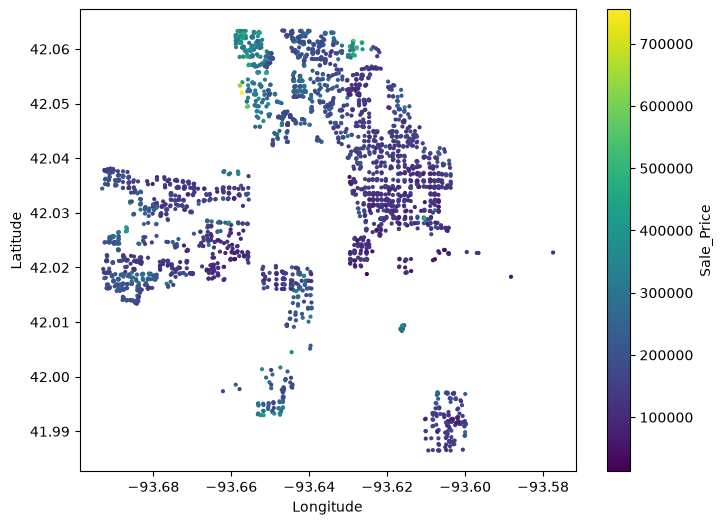

In [4]:
df.plot.scatter(x="Longitude", y="Latitude", c="Sale_Price",
                cmap="viridis", s=4, figsize=(8, 6));

In [5]:
df["Sale_Price"].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: Sale_Price, dtype: float64

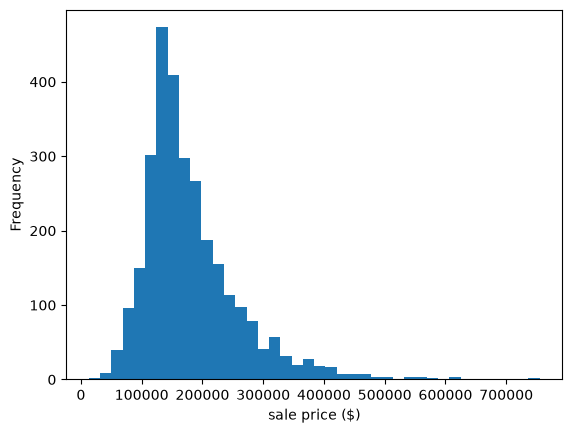

In [6]:
df["Sale_Price"].plot.hist(bins=40, xlabel="sale price ($)");

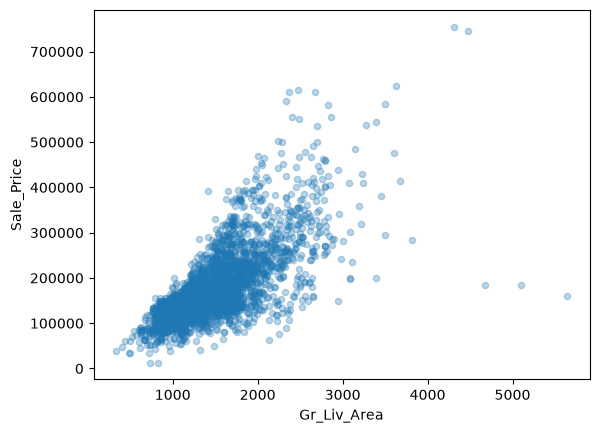

In [7]:
df.plot.scatter(x="Gr_Liv_Area", y="Sale_Price", alpha=0.3);

In [8]:
big = df[df["Gr_Liv_Area"] > 4000]
big[["Neighborhood", "Year_Built", "Sale_Condition", "Gr_Liv_Area",
     "Sale_Price"]]

,Neighborhood,Year_Built,Sale_Condition,Gr_Liv_Area,Sale_Price
1498,Edwards,2008,Partial,5642,160000
1760,Northridge,1996,Abnorml,4476,745000
1767,Northridge,1994,Normal,4316,755000
2180,Edwards,2008,Partial,5095,183850
2181,Edwards,2007,Partial,4676,184750


In [9]:
order = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average",
         "Above_Average", "Good", "Very_Good", "Excellent",
         "Very_Excellent"]
scores = dict(zip(order, range(1, 11)))
df["quality"] = df["Overall_Qual"].map(scores).astype(int)
df.groupby("quality")["Sale_Price"].median()

quality
1      50150.0
2      57625.0
3      81200.0
4     105000.0
5     133000.0
6     159500.0
7     200000.0
8     264530.5
9     360000.0
10    451950.0
Name: Sale_Price, dtype: float64

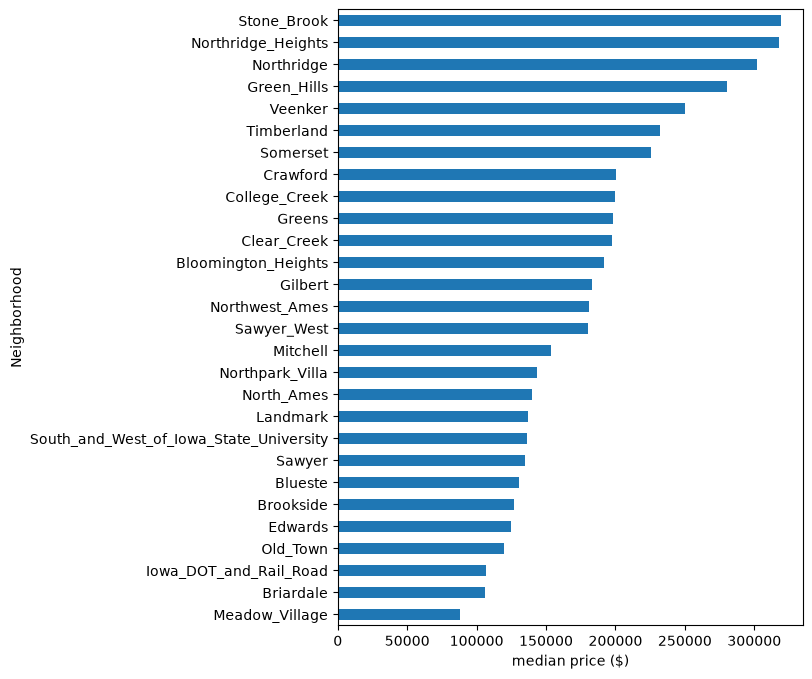

In [10]:
places = df.groupby("Neighborhood")["Sale_Price"].median().sort_values()
places.plot.barh(xlabel="median price ($)", figsize=(6, 8));

In [11]:
df.groupby("Year_Sold")["Sale_Price"].median()

Year_Sold
2006    159500.0
2007    165125.0
2008    161000.0
2009    160850.0
2010    155000.0
Name: Sale_Price, dtype: float64

In [12]:
corr = df.corr(numeric_only=True)["Sale_Price"]
corr.sort_values(ascending=False).head(10)

Sale_Price        1.000000
quality           0.799262
Gr_Liv_Area       0.706780
Garage_Cars       0.647562
Garage_Area       0.640138
Total_Bsmt_SF     0.632529
First_Flr_SF      0.621676
Year_Built        0.558426
Full_Bath         0.545604
Year_Remod_Add    0.532974
Name: Sale_Price, dtype: float64

In [13]:
df = df[df["Gr_Liv_Area"] <= 4000]
len(df)

2925

In [14]:
features = ["quality", "Gr_Liv_Area", "Total_Bsmt_SF", "Garage_Cars",
            "Year_Built"]
X = df[features]
y = df["Sale_Price"]
X.head()

,quality,Gr_Liv_Area,Total_Bsmt_SF,Garage_Cars,Year_Built
0,6,1656,1080,2,1960
1,5,896,882,1,1961
2,6,1329,1329,1,1958
3,7,2110,2110,2,1968
4,5,1629,928,2,1997


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0)
len(X_train), len(X_test)

(2193, 732)

Mean absolute error: $\text{MAE} = \dfrac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert$

In [16]:
from sklearn.metrics import mean_absolute_error

middle = [y_train.median()] * len(y_test)
mean_absolute_error(y_test, middle)

54557.83196721312

In [17]:
from sklearn.linear_model import LinearRegression

line = LinearRegression()
line.fit(X_train[["Gr_Liv_Area"]], y_train)
line.coef_, line.intercept_

(array([117.63041453]), np.float64(5924.172383043391))

Least squares: the line with the smallest $\sum_{i=1}^{n} (y_i - \hat{y}_i)^2$

In [18]:
mean_absolute_error(y_test, line.predict(X_test[["Gr_Liv_Area"]]))

37564.42247748802

A line with five facts: $\hat{y} = b + w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5$

In [19]:
model = LinearRegression()
model.fit(X_train, y_train)
pd.Series(model.coef_, index=features).round()

quality          19380.0
Gr_Liv_Area         56.0
Total_Bsmt_SF       46.0
Garage_Cars      11045.0
Year_Built         322.0
dtype: float64

In [20]:
guess = model.predict(X_test)
pd.DataFrame({"guess": guess.round(-3), "truth": y_test}).head()

,guess,truth
2128,228000.0,235500
722,104000.0,85000
1797,271000.0,270000
2185,87000.0,111000
305,82000.0,102776


In [21]:
mean_absolute_error(y_test, guess)

24421.604967399475

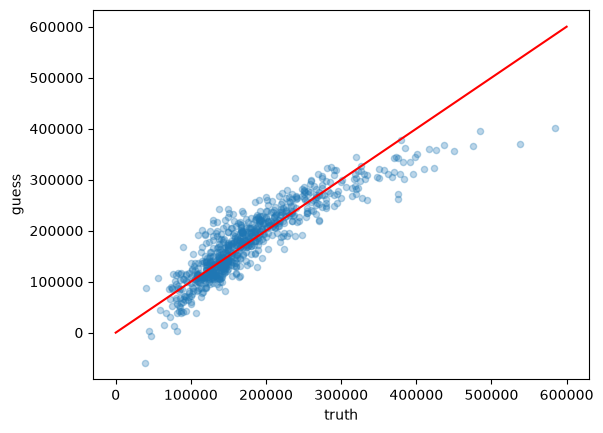

In [22]:
ax = pd.DataFrame({"truth": y_test, "guess": guess}).plot.scatter(
    x="truth", y="guess", alpha=0.3)
ax.plot([0, 600000], [0, 600000], color="red");

In [23]:
from sklearn.tree import DecisionTreeRegressor

tree = DecisionTreeRegressor(max_depth=3, random_state=0)
tree.fit(X_train, y_train)
mean_absolute_error(y_test, tree.predict(X_test))

29758.244416543344

How spread out a group's prices are: $\sqrt{\dfrac{1}{n}\sum_{i=1}^{n} (y_i - \bar{y})^2}$

In [24]:
def spread(prices):
    return ((prices - prices.mean()) ** 2).mean() ** 0.5

round(spread(y_train))

79569

In [25]:
fine = X_train["quality"] >= 8
round(spread(y_train[~fine])), round(spread(y_train[fine]))

(48290, 88350)

In [26]:
from sklearn.model_selection import cross_val_score

def cv_error(model):
    scores = cross_val_score(model, X_train, y_train, cv=5,
                             scoring="neg_mean_absolute_error")
    return round(-scores.mean())

for depth in [2, 4, 6, 8, 10, None]:
    t = DecisionTreeRegressor(max_depth=depth, random_state=0)
    print(depth, cv_error(t))

2 34149
4 26171
6 23114
8 23211
10 23443
None 26177


In [27]:
cv_error(LinearRegression())

23825

In [28]:
final = DecisionTreeRegressor(max_depth=6, random_state=0)
final.fit(X_train, y_train)
mean_absolute_error(y_test, final.predict(X_test))

23098.69049773398

In [29]:
pd.DataFrame({"line": guess[:5].round(-3),
              "tree": final.predict(X_test[:5]).round(-3),
              "truth": y_test[:5]})

,line,tree,truth
2128,228000.0,207000.0,235500
722,104000.0,104000.0,85000
1797,271000.0,270000.0,270000
2185,87000.0,86000.0,111000
305,82000.0,106000.0,102776


In [30]:
ours = pd.DataFrame({"quality": [6], "Gr_Liv_Area": [1500],
                     "Total_Bsmt_SF": [1000], "Garage_Cars": [2],
                     "Year_Built": [1975]})
final.predict(ours).round(-3)

array([156000.])

In [31]:
for seed in range(5):
    some = X_train.sample(frac=0.8, random_state=seed)
    t = DecisionTreeRegressor(max_depth=6, random_state=0)
    t.fit(some, y_train[some.index])
    print(seed, t.predict(ours).round(-3))

0 [154000.]
1 [154000.]
2 [186000.]
3 [183000.]
4 [155000.]
